In [5]:
!pip install split-folders mlflow dagshub

In [6]:
import dagshub
import mlflow

# This connects your Kaggle notebook to your free remote dashboard
#change the username to your and create a reposotry
dagshub.init("tomato-grading", "afkirmohamad4", mlflow=True)
mlflow.tensorflow.autolog()

Initialized MLflow to track repo "afkirmohamad4/tomato-grading"

Repository afkirmohamad4/tomato-grading initialized!

In [7]:
import cv2 
import tensorflow as tf
import os
import numpy as np 


data_dir = '/kaggle/input/datasets/mohamedafkir90/tomato-quality-classification/Clean_tomato_dataset/Clean_tomato_dataset'
    
valid_extensions = ['.jpeg', '.jpg', '.png' ,'bmp']

#test function
def is_valid_image(file_path):
    # 1. Check if the file extension is correct
    ext = os.path.splitext(file_path)[1].lower()
    if ext not in valid_extensions:
        return False
        
    # try opening the image with OpenCV
    img = cv2.imread(file_path)
    if img is None:
        return False
        
    return True

In [8]:
os.listdir(data_dir)

['Local', 'Export', 'Rotten']

In [9]:
import splitfolders
from matplotlib import pyplot as plt

In [10]:
input_folder = '/kaggle/input/datasets/mohamedafkir90/tomato-quality-classification/Clean_tomato_dataset/Clean_tomato_dataset'
output_folder = '/kaggle/working/tomato_split' # Save to the writable directory

splitfolders.ratio(input_folder, 
                   output=output_folder, 
                   seed=42, 
                   ratio=(.8, .1, .1), # (train, val, test)
                   group_prefix=None, 
                   move=False) # Use False to copy files

Copying files: 15408 files [01:15, 205.27 files/s]


In [11]:
BATCH_SIZE =32
IMG_SIZE = (224, 224) 

# Explicitly tell TensorFlow which folders to care about
TARGET_CLASSES = ['Export', 'Local', 'Rotten']

train_ds = tf.keras.utils.image_dataset_from_directory(
    '/kaggle/working/tomato_split/train',
    class_names=TARGET_CLASSES, # <--- Change is right here!
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    '/kaggle/working/tomato_split/val',
    class_names=TARGET_CLASSES, # <--- Change is right here!
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    '/kaggle/working/tomato_split/test',
    class_names=TARGET_CLASSES, # <--- Change is right here!
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
print("\n classes are:", class_names)

Found 12324 files belonging to 3 classes.


I0000 00:00:1778790494.264575      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Found 1539 files belonging to 3 classes.
Found 1545 files belonging to 3 classes.

 classes are: ['Export', 'Local', 'Rotten']


In [12]:
data_iterator = train_ds.as_numpy_iterator()

In [13]:
data_iterator

NumpyIterator(iterator=<tensorflow.python.data.ops.iterator_ops.OwnedIterator object at 0x7c14dc7fe5a0>)

In [14]:
batch = data_iterator.next()

In [15]:
batch[1]

array([2, 0, 2, 2, 0, 0, 2, 2, 1, 0, 1, 0, 2, 2, 0, 1, 1, 0, 0, 0, 1, 0,
       0, 1, 2, 1, 1, 1, 2, 2, 0, 1], dtype=int32)

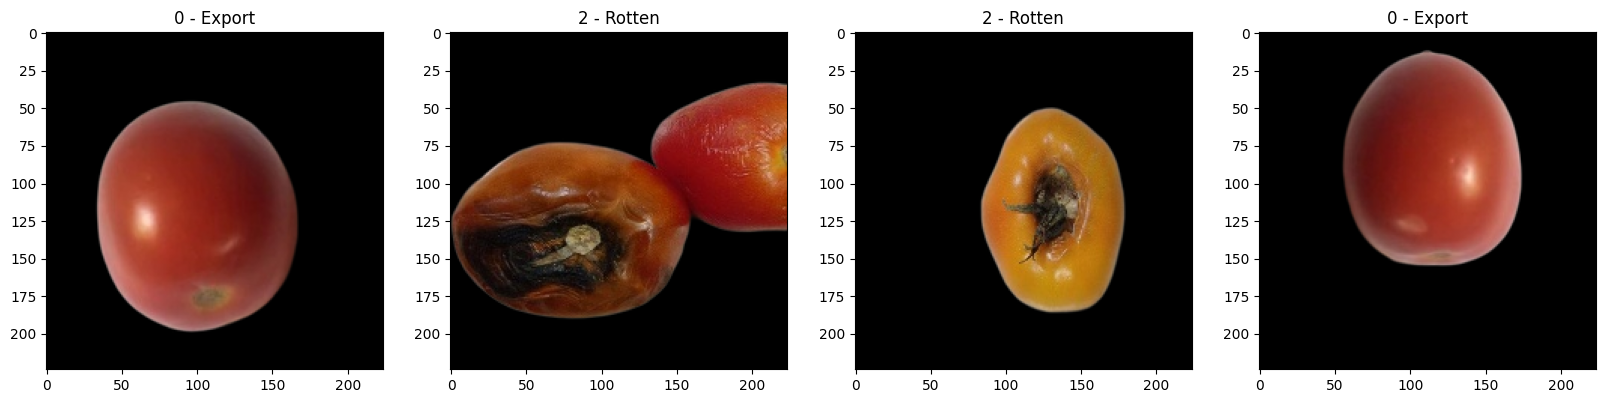

In [16]:
fig, ax = plt.subplots(ncols=4, figsize=(20,20))

start_idx = 11

for i in range(4):
    true_idx = start_idx + i 
    
    img = batch[0][true_idx]
    label_id = batch[1][true_idx]
    
    ax[i].imshow(img.astype(int))
    ax[i].title.set_text(f"{label_id} - {class_names[label_id]}")

#### Class 0: Export
#### Class 1: Local
#### Class 2: Rotten

In [17]:
Train_data = train_ds.map(lambda x,y: (x/255,y))

Val_data = val_ds.map(lambda x,y: (x/255,y))

Test_data = test_ds.map(lambda x,y: (x/255,y))

In [18]:
batch[0].max()

np.float32(255.0)

In [20]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dense,GlobalAveragePooling2D, Flatten, Dropout

In [21]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, BatchNormalization, Dropout, Dense
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.optimizers import Adam

print(" Building the Golden Architecture...")
tf.keras.backend.clear_session() 

# 1. Load the pre-trained Google brain
base_model = EfficientNetB0(input_shape=(224, 224, 3), 
                            include_top=False, 
                            weights='imagenet')

# Freeze the base so we don't destroy its pre-trained edge detection
base_model.trainable = False

# 2. Build our custom grading head
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    
    # The hero layer that prevented the Keras math from exploding
    BatchNormalization(),
    
    Dropout(0.2), 
    
    # Direct connection to the 3 classes
    Dense(3, activation='softmax')
])

# 3. Compile the model
custom_optimizer = Adam(learning_rate=0.001)

model.compile(optimizer=custom_optimizer, 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

model.summary()

 Building the Golden Architecture...
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,534 (15.48 MB)

 Trainable params: 6,403 (25.01 KB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [22]:
import os
import tensorflow as tf
import mlflow

models_dir = "/kaggle/working/models"
os.makedirs(models_dir, exist_ok=True)

latest_model_path = os.path.join(models_dir, "Tomato_grading_v9.keras")
best_model_path = os.path.join(models_dir, "Tomato_grading_BEST.keras")


if os.path.exists(latest_model_path):
    print(f" Found latest model! Resuming training from: {latest_model_path}")
    model = tf.keras.models.load_model(latest_model_path)
else:
    print(" No latest model found. Starting fresh training with the defined architecture...")
    

callbacks = [
    
    
    tf.keras.callbacks.ModelCheckpoint(best_model_path, monitor='val_loss', save_best_only=True),
    
   
    tf.keras.callbacks.ModelCheckpoint(latest_model_path, monitor='val_loss', save_best_only=False)
]


if mlflow.active_run():
    mlflow.end_run()


print(" Starting training with MLflow tracking...")
with mlflow.start_run(run_name="EfficientNet_Resumed_v9"):
    
    mlflow.log_param("batch_size", 128)
    mlflow.log_param("image_size", "224x224")
    mlflow.log_param("architecture", "EfficientNetB0")
    mlflow.log_param("is_resumed", os.path.exists(latest_model_path)) 
    
    history = model.fit(
        train_ds, 
        validation_data=val_ds, 
        epochs=20, 
        callbacks=callbacks 
    )

    print(" Forcing metrics to DagsHub...")
    for metric_name, values in history.history.items():
        for epoch, value in enumerate(values):
            mlflow.log_metric(metric_name, value, step=epoch)

print(" Training complete. Latest and Best models updated!")

 No latest model found. Starting fresh training with the defined architecture...
 Starting training with MLflow tracking...
Epoch 1/20


I0000 00:00:1778790509.817452     171 service.cc:152] XLA service 0x7c140c00b440 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1778790509.817522     171 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1778790512.150725     171 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1778790523.142934     171 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


386/386 ━━━━━━━━━━━━━━━━━━━━ 59s 95ms/step - accuracy: 0.8898 - loss: 0.2790 - val_accuracy: 0.9740 - val_loss: 0.0884
Epoch 2/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.9692 - loss: 0.0923 - val_accuracy: 0.9864 - val_loss: 0.0554
Epoch 3/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.9732 - loss: 0.0763 - val_accuracy: 0.9857 - val_loss: 0.0423
Epoch 4/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.9750 - loss: 0.0692 - val_accuracy: 0.9877 - val_loss: 0.0381
Epoch 5/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - accuracy: 0.9785 - loss: 0.0611 - val_accuracy: 0.9877 - val_loss: 0.0423
Epoch 6/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.9751 - loss: 0.0664 - val_accuracy: 0.9857 - val_loss: 0.0408
Epoch 7/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.9787 - loss: 0.0570 - val_accuracy: 0.9896 - val_loss: 0.0359
Epoch 8/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.9809 - loss: 0.0558 - val_accurac

2026/05/14 20:33:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during tensorflow autologging: INVALID_PARAMETER_VALUE: Response: {'error_code': 'INVALID_PARAMETER_VALUE'}


 Forcing metrics to DagsHub...
🏃 View run EfficientNet_Resumed_v9 at: https://dagshub.com/afkirmohamad4/tomato-grading.mlflow/#/experiments/0/runs/a4cb968bef9d4b539ad716064de42d87
🧪 View experiment at: https://dagshub.com/afkirmohamad4/tomato-grading.mlflow/#/experiments/0
 Training complete. Latest and Best models updated!


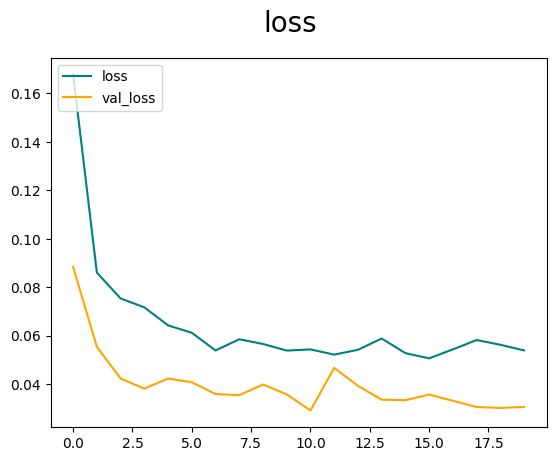

In [23]:
fig = plt.figure
plt.plot(history.history['loss'],color='teal', label='loss')
plt.plot(history.history['val_loss'],color='orange', label='val_loss')
plt.suptitle('loss',fontsize=20)
plt.legend(loc='upper left')
plt.show()

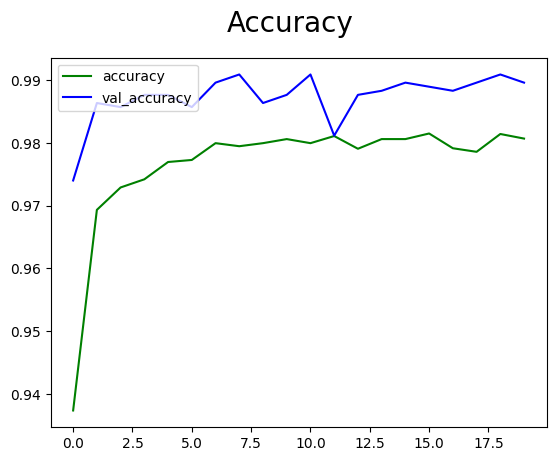

In [24]:
fig = plt.figure
plt.plot(history.history['accuracy'],color='green', label='accuracy')
plt.plot(history.history['val_accuracy'],color='blue', label='val_accuracy')
plt.suptitle('Accuracy',fontsize=20)
plt.legend(loc='upper left')
plt.show()

In [25]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np


model.load_weights("/kaggle/working/models/Tomato_grading_v9.keras")

y_true_all = []
y_pred_all = []

for batch in Test_data.as_numpy_iterator():
    X, y = batch
    
    y_predict_probs = model.predict(X, verbose=0)
    y_predict_classes = np.argmax(y_predict_probs, axis=1)
    
    y_true_all.extend(y)
    y_pred_all.extend(y_predict_classes)

print("Classification Report:")
print(classification_report(y_true_all, y_pred_all, target_names=['Export', 'Local', 'Rotten']))

Classification Report:
              precision    recall  f1-score   support

      Export       0.33      1.00      0.50       515
       Local       0.00      0.00      0.00       515
      Rotten       0.00      0.00      0.00       515

    accuracy                           0.33      1545
   macro avg       0.11      0.33      0.17      1545
weighted avg       0.11      0.33      0.17      1545



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [26]:
model_path = '/kaggle/working/models/Tomato_grading_v9.keras'
size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f"Model size: {size_mb:.2f} MB")

Model size: 16.34 MB


In [27]:
import tensorflow as tf

print("Loading the best model...")
model = tf.keras.models.load_model("/kaggle/working/models/Tomato_grading_BEST.keras")

print("Exporting to Universal SavedModel format...")
# 🛑 THE FIX: Use model.export() instead of model.save()
model.export("/kaggle/working/models/Tomato_grading_Universal")

print("Done! Download the entire Tomato_grading_Universal folder.")

Loading the best model...
Exporting to Universal SavedModel format...
INFO:tensorflow:Assets written to: /kaggle/working/models/Tomato_grading_Universal/assets


INFO:tensorflow:Assets written to: /kaggle/working/models/Tomato_grading_Universal/assets


Saved artifact at '/kaggle/working/models/Tomato_grading_Universal'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  136424866480592: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  136424866486544: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  136425211186832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136425211188560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136425211187408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136425211190096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136425211193360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136425211191248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136425211189136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136425211193168: TensorSpec(shape=

In [28]:
import shutil

print("Zipping the Universal Model folder...")

# shutil.make_archive(output_filename, 'zip', directory_to_zip)
shutil.make_archive("/kaggle/working/Tomato_grading_Universal", 'zip', "/kaggle/working/models/Tomato_grading_Universal")

print("Done! You can now download Tomato_grading_Universal.zip from the output panel.")

Zipping the Universal Model folder...
Done! You can now download Tomato_grading_Universal.zip from the output panel.
